In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROCESSED = Path("../data/processed")
REPORTS = Path("../reports")
REPORTS.mkdir(exist_ok=True)

mart = pd.read_parquet(
    PROCESSED / "mart_manufacturer_drug_month.parquet"
)

mart["event_month"] = pd.to_datetime(mart["event_month"])
mart = mart.sort_values(["manufacturer", "drug_name", "event_month"])

print(mart.shape)
mart.head()

(1362400, 21)


,manufacturer,drug_name,event_month,events_count,batches_count,letters_count,regions_affected,first_event_date,last_event_date,events_lag_1m,...,events_lag_6m,events_rolling_3m,events_rolling_6m,events_rolling_12m,events_rolling_3m_mean,events_rolling_12m_mean,risk_flag_spike,risk_flag_repeated,risk_flag_active_month,risk_score_v0
0,,аримидекс,2005-01-01,0.0,0.0,0.0,0.0,NaT,NaT,NaN,...,NaN,0.0,0.0,0.0,0.0,0.0,0,0,0,0
1,,аримидекс,2005-02-01,0.0,0.0,0.0,0.0,NaT,NaT,0.0,...,NaN,0.0,0.0,0.0,0.0,0.0,0,0,0,0
2,,аримидекс,2005-03-01,0.0,0.0,0.0,0.0,NaT,NaT,0.0,...,NaN,0.0,0.0,0.0,0.0,0.0,0,0,0,0
3,,аримидекс,2005-04-01,0.0,0.0,0.0,0.0,NaT,NaT,0.0,...,NaN,0.0,0.0,0.0,0.0,0.0,0,0,0,0
4,,аримидекс,2005-05-01,0.0,0.0,0.0,0.0,NaT,NaT,0.0,...,NaN,0.0,0.0,0.0,0.0,0.0,0,0,0,0


In [2]:
required_columns = [
    "manufacturer",
    "drug_name",
    "event_month",
    "events_count",
    "batches_count",
    "letters_count",
]

missing_columns = [
    column for column in required_columns
    if column not in mart.columns
]

assert not missing_columns, f"Нет колонок: {missing_columns}"

mart[required_columns].head()

,manufacturer,drug_name,event_month,events_count,batches_count,letters_count
0,,аримидекс,2005-01-01,0.0,0.0,0.0
1,,аримидекс,2005-02-01,0.0,0.0,0.0
2,,аримидекс,2005-03-01,0.0,0.0,0.0
3,,аримидекс,2005-04-01,0.0,0.0,0.0
4,,аримидекс,2005-05-01,0.0,0.0,0.0


In [4]:
group_columns = ["manufacturer", "drug_name"]

mart["events_median_prev_12m"] = (
    mart
    .groupby(group_columns)["events_count"]
    .transform(
        lambda series: series.shift(1)
        .rolling(window=12, min_periods=6)
        .median()
    )
)

mart.head(10)

,manufacturer,drug_name,event_month,events_count,batches_count,letters_count,regions_affected,first_event_date,last_event_date,events_lag_1m,...,events_rolling_3m,events_rolling_6m,events_rolling_12m,events_rolling_3m_mean,events_rolling_12m_mean,risk_flag_spike,risk_flag_repeated,risk_flag_active_month,risk_score_v0,events_median_prev_12m
0,,аримидекс,2005-01-01,0.0,0.0,0.0,0.0,NaT,NaT,NaN,...,0.0,0.0,0.0,0.0,0.0,0,0,0,0,NaN
1,,аримидекс,2005-02-01,0.0,0.0,0.0,0.0,NaT,NaT,0.0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,0,NaN
2,,аримидекс,2005-03-01,0.0,0.0,0.0,0.0,NaT,NaT,0.0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,0,NaN
3,,аримидекс,2005-04-01,0.0,0.0,0.0,0.0,NaT,NaT,0.0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,0,NaN
4,,аримидекс,2005-05-01,0.0,0.0,0.0,0.0,NaT,NaT,0.0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,0,NaN
5,,аримидекс,2005-06-01,0.0,0.0,0.0,0.0,NaT,NaT,0.0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,0,NaN
6,,аримидекс,2005-07-01,0.0,0.0,0.0,0.0,NaT,NaT,0.0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0.0
7,,аримидекс,2005-08-01,0.0,0.0,0.0,0.0,NaT,NaT,0.0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0.0
8,,аримидекс,2005-09-01,0.0,0.0,0.0,0.0,NaT,NaT,0.0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0.0
9,,аримидекс,2005-10-01,0.0,0.0,0.0,0.0,NaT,NaT,0.0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0.0


In [5]:
mart["events_ratio_to_median_12m"] = (
    mart["events_count"]
    / mart["events_median_prev_12m"].replace(0, np.nan)
)

mart[
    [
        "manufacturer",
        "drug_name",
        "event_month",
        "events_count",
        "events_median_prev_12m",
        "events_ratio_to_median_12m",
    ]
].head(20)

,manufacturer,drug_name,event_month,events_count,events_median_prev_12m,events_ratio_to_median_12m
0,,аримидекс,2005-01-01,0.0,NaN,NaN
1,,аримидекс,2005-02-01,0.0,NaN,NaN
2,,аримидекс,2005-03-01,0.0,NaN,NaN
3,,аримидекс,2005-04-01,0.0,NaN,NaN
4,,аримидекс,2005-05-01,0.0,NaN,NaN
5,,аримидекс,2005-06-01,0.0,NaN,NaN
6,,аримидекс,2005-07-01,0.0,0.0,NaN
7,,аримидекс,2005-08-01,0.0,0.0,NaN
8,,аримидекс,2005-09-01,0.0,0.0,NaN
9,,аримидекс,2005-10-01,0.0,0.0,NaN


In [6]:
mart["anomaly_flag_simple"] = (
    (mart["events_count"] >= 2)
    & (mart["events_ratio_to_median_12m"] >= 3)
).astype(int)

mart["anomaly_flag_simple"].value_counts()

anomaly_flag_simple
0    1361989
1        411
Name: count, dtype: int64

In [7]:
mart["risk_score_simple"] = (
    40 * (mart["anomaly_flag_simple"] == 1).astype(int)
    + 25 * (mart["events_rolling_3m"] >= 2).astype(int)
    + 15 * (mart["events_count"] >= 2).astype(int)
    + 10 * (mart["events_ratio_to_median_12m"] >= 2).astype(int)
    + 10 * (mart["events_rolling_6m"] >= 3).astype(int)
)

In [8]:
mart

,manufacturer,drug_name,event_month,events_count,batches_count,letters_count,regions_affected,first_event_date,last_event_date,events_lag_1m,...,events_rolling_3m_mean,events_rolling_12m_mean,risk_flag_spike,risk_flag_repeated,risk_flag_active_month,risk_score_v0,events_median_prev_12m,events_ratio_to_median_12m,anomaly_flag_simple,risk_score_simple
0,,аримидекс,2005-01-01,0.0,0.0,0.0,0.0,NaT,NaT,NaN,...,0.0,0.0,0,0,0,0,NaN,NaN,0,0
1,,аримидекс,2005-02-01,0.0,0.0,0.0,0.0,NaT,NaT,0.0,...,0.0,0.0,0,0,0,0,NaN,NaN,0,0
2,,аримидекс,2005-03-01,0.0,0.0,0.0,0.0,NaT,NaT,0.0,...,0.0,0.0,0,0,0,0,NaN,NaN,0,0
3,,аримидекс,2005-04-01,0.0,0.0,0.0,0.0,NaT,NaT,0.0,...,0.0,0.0,0,0,0,0,NaN,NaN,0,0
4,,аримидекс,2005-05-01,0.0,0.0,0.0,0.0,NaT,NaT,0.0,...,0.0,0.0,0,0,0,0,NaN,NaN,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1362395,ярославская фармфабрика зао,элеутерококка экстракт жидкий,2026-06-01,0.0,0.0,0.0,0.0,NaT,NaT,0.0,...,0.0,0.0,0,0,0,0,0.0,NaN,0,0
1362396,ярославская фармфабрика зао,элеутерококка экстракт жидкий,2026-07-01,0.0,0.0,0.0,0.0,NaT,NaT,0.0,...,0.0,0.0,0,0,0,0,0.0,NaN,0,0
1362397,ярославская фармфабрика зао,элеутерококка экстракт жидкий,2026-08-01,0.0,0.0,0.0,0.0,NaT,NaT,0.0,...,0.0,0.0,0,0,0,0,0.0,NaN,0,0
1362398,ярославская фармфабрика зао,элеутерококка экстракт жидкий,2026-09-01,0.0,0.0,0.0,0.0,NaT,NaT,0.0,...,0.0,0.0,0,0,0,0,0.0,NaN,0,0


In [9]:
mart["risk_category"] = pd.cut(
    mart["risk_score_simple"],
    bins=[-1, 24, 49, 74, 100],
    labels=["low", "medium", "high", "critical"],
)

mart["risk_category"].value_counts()

risk_category
low         1347561
medium        11039
high           3389
critical        411
Name: count, dtype: int64

In [10]:
last_month = mart["event_month"].max()

top_risk = (
    mart[mart["event_month"] == last_month]
    .sort_values(
        ["risk_score_simple", "events_count"],
        ascending=[False, False],
    )
    .head(20)
)

top_risk[
    [
        "event_month",
        "manufacturer",
        "drug_name",
        "events_count",
        "events_rolling_3m",
        "events_median_prev_12m",
        "events_ratio_to_median_12m",
        "risk_score_simple",
        "risk_category",
    ]
]

,event_month,manufacturer,drug_name,events_count,events_rolling_3m,events_median_prev_12m,events_ratio_to_median_12m,risk_score_simple,risk_category
760061,2026-10-01,"общество с ограниченной ответственностью ""велф...",ибупрофен велфарм,1.0,3.0,0.0,NaN,35,medium
795955,2026-10-01,"общество с ограниченной ответственностью ""прои...",симетикон,1.0,2.0,0.0,NaN,35,medium
965731,2026-10-01,"публичное акционерное общество ""акционерное ку...",кеторолак,1.0,6.0,0.0,NaN,35,medium
104013,2026-10-01,"ао ""производственная фармацевтическая компания...",фуросемид буфус,0.0,4.0,0.0,NaN,35,medium
791501,2026-10-01,"общество с ограниченной ответственностью ""пран...",амлодипин-прана,0.0,8.0,2.0,0.0,35,medium
802505,2026-10-01,"общество с ограниченной ответственностью ""туль...",винилин (шостаковского бальзам),0.0,5.0,0.0,NaN,35,medium
867481,2026-10-01,"ооо ""производство медикаментов""",индапамид,0.0,3.0,0.0,NaN,35,medium
1231661,2026-10-01,"федеральное казенное предприятие ""армавирская ...",кальция глюконат,0.0,4.0,0.0,NaN,35,medium
48993,2026-10-01,"акционерное общество ""брынцалов-а"" (ао ""брынца...",рифампицин-ферейн,0.0,2.0,0.0,NaN,25,medium
795693,2026-10-01,"общество с ограниченной ответственностью ""прои...",индапамид,0.0,2.0,0.0,NaN,25,medium


In [13]:
example = top_risk.iloc[2]

example_mask = (
    (mart["manufacturer"] == example["manufacturer"])
    & (mart["drug_name"] == example["drug_name"])
)

example_history = mart[example_mask].sort_values("event_month")

example_history[
    [
        "event_month",
        "events_count",
        "events_median_prev_12m",
        "events_ratio_to_median_12m",
        "risk_score_simple",
        "risk_category",
    ]
].tail(24)

,event_month,events_count,events_median_prev_12m,events_ratio_to_median_12m,risk_score_simple,risk_category
965708,2024-11-01,0.0,0.0,NaN,0,low
965709,2024-12-01,0.0,0.0,NaN,0,low
965710,2025-01-01,0.0,0.0,NaN,0,low
965711,2025-02-01,0.0,0.0,NaN,0,low
965712,2025-03-01,0.0,0.0,NaN,0,low
965713,2025-04-01,0.0,0.0,NaN,0,low
965714,2025-05-01,0.0,0.0,NaN,0,low
965715,2025-06-01,0.0,0.0,NaN,0,low
965716,2025-07-01,0.0,0.0,NaN,0,low
965717,2025-08-01,0.0,0.0,NaN,0,low


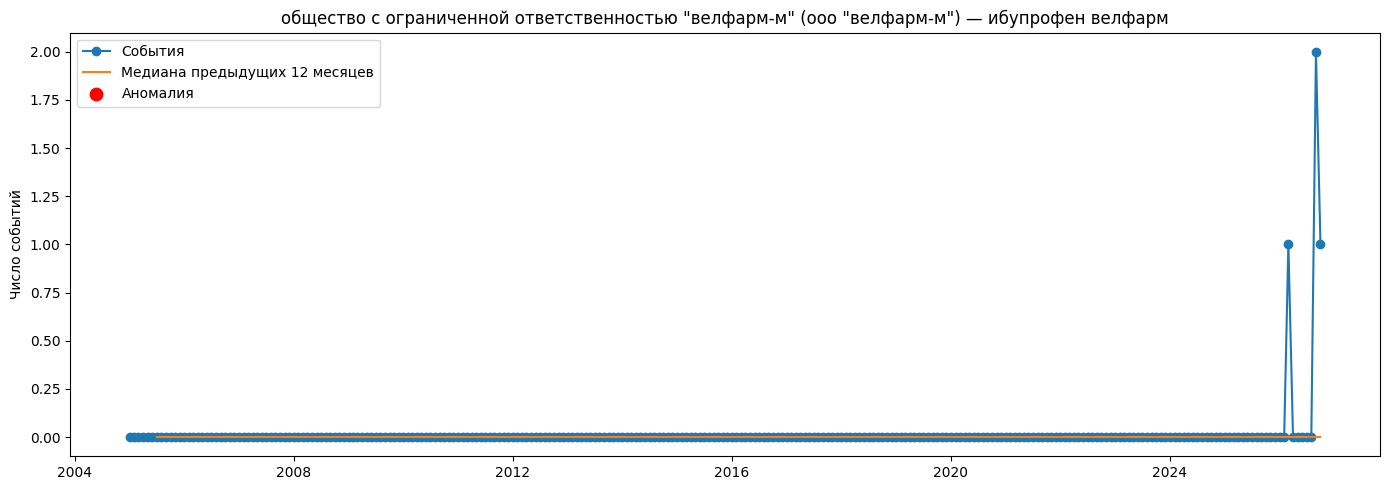

In [12]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    example_history["event_month"],
    example_history["events_count"],
    marker="o",
    label="События",
)

ax.plot(
    example_history["event_month"],
    example_history["events_median_prev_12m"],
    label="Медиана предыдущих 12 месяцев",
)

anomalies = example_history[
    example_history["anomaly_flag_simple"] == 1
]

ax.scatter(
    anomalies["event_month"],
    anomalies["events_count"],
    color="red",
    s=80,
    label="Аномалия",
)

ax.set_title(
    f"{example['manufacturer']} — {example['drug_name']}"
)
ax.set_ylabel("Число событий")
ax.legend()

fig.tight_layout()
fig.savefig(
    REPORTS / "simple_anomaly_example.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

In [14]:
mart.to_parquet(
    PROCESSED / "mart_manufacturer_drug_month_simple_score.parquet",
    index=False,
)